# La batería de validación IFRS 9 en seis fechas de reporte

**Pregunta:** ¿Pasa el modelo IFRS 9 de un prestamista de pequeñas empresas la batería de validación de los supervisores, en qué pruebas y en cuál de seis fechas de reporte falla, y qué puede concluir un validador cuando una prueba no se puede evaluar?

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** los cuadernos 01 a 04 de este tema
- **Tiempo de lectura:** unos 55 minutos

## Objetivos

Al terminar este cuaderno puedes:

- listar las pruebas de la batería de IFRS 9, qué pregunta cada una y de qué expectativa supervisora viene;
- leer la prueba retrospectiva de la PD de vida completa por cohorte de origen y por decil, y decir qué significa la luz del motor y qué no;
- leer la efectividad del SICR, la estabilidad del umbral, la migración de etapas y la prueba retrospectiva de la PCE, recalcular las que el artefacto guarda con sus insumos, y nombrar las que no;
- decir qué concluye un validador cuando una prueba no es evaluable, y por qué eso no es un aprobado;
- comparar la batería en una crisis, una recuperación, un período tranquilo y el choque de la pandemia sobre una misma cartera.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch
for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))
LIGHT = {"green": "verde", "amber": "ámbar", "red": "rojo", "not_evaluated": "no evaluada"}
COLOR = {"green": "#2e8b57", "amber": "#e6a117", "red": "#c0392b", "not_evaluated": "#b0b0b0"}
TEST_NAME = {
    "lifetime_pd_backtest": "prueba retrospectiva de la PD de vida completa",
    "sicr_effectiveness": "efectividad del SICR",
    "sicr_threshold_stability": "estabilidad del umbral SICR",
    "stage_migration_backtest": "prueba retrospectiva de migración de etapas",
    "ecl_backtest": "prueba retrospectiva de la PCE",
    "scenario_sensitivity": "sensibilidad a escenarios",
    "nonlinearity": "no linealidad",
    "overlay_diagnostics": "diagnóstico de ajustes",
    "reconciliation_identities": "identidades de conciliación",
}

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Los datos son las seis fechas de reporte del caso C06 (préstamos 7(a) de la SBA, Obras del Gobierno de EE. UU., clase de licencia `mirror-allowed`): 2006-12-31 (antes de la crisis), 2008-12-31 y 2010-12-31 (la crisis y la recuperación), 2019-12-31 (un año tranquilo), 2020-06-30 (el choque de la pandemia) y 2023-06-30. Cada archivo `data/derived/C06/rd-<fecha>.json` guarda las filas de la batería en `tests` y los insumos que el flujo de cálculo conservó en `outputs`: la prueba retrospectiva de vida completa por cohorte de origen (`lifetime_backtest`), la calibración por decil (`decile_calibration`), el resumen por etapa y la PCE ponderada y de un solo escenario.

Una fila de `tests` es el `TestResult` del motor tal como lo versionó el flujo de cálculo: el identificador de la prueba, el modelo (el peldaño del cuaderno 07: `L0-km`, `L1-dth` o `L2-cox`), el segmento (una cohorte de origen para la prueba de vida completa), la métrica o el valor p, la luz y los `extras`. Cada prueba es una **compuerta interna** de Contraste, no un umbral regulatorio, y cada fila registra los parámetros que usó en `policy_version`.

El cuaderno imprime la versión del motor que calculó los archivos junto a la versión instalada ahora, y recalcula solo las pruebas cuyos insumos están en el archivo.

In [2]:
# Cargar las seis fechas de reporte e indexar la fila a nivel de cartera de cada prueba
from riskvalidation.validation import ifrs9

ROOT = Path("../../..").resolve()
DATES = ("2006-12", "2008-12", "2010-12", "2019-12", "2020-06", "2023-06")
DERIVED = ROOT / "data" / "derived" / "C06"
cases = {d: json.loads((DERIVED / f"rd-{d}.json").read_text(encoding="utf-8")) for d in DATES}
tests = {d: {} for d in DATES}
for d, case in cases.items():
    for t in case["tests"]:
        if t["segment"] in (None, "all") and t["model_id"] == "L1-dth":
            tests[d].setdefault(t["test_id"], t)
baked = sorted({c["provenance"]["riskvalidation_version"] for c in cases.values()})
print("motor que calculó los seis artefactos:", *baked, "| motor instalado ahora:", md.version("riskvalidation"))
print("filas de prueba por fecha:", len(cases["2008-12"]["tests"]), "| pruebas distintas:", len(tests["2008-12"]))

motor que calculó los seis artefactos: 1.0.1 | motor instalado ahora: 1.0.1
filas de prueba por fecha: 29 | pruebas distintas: 9


## Método

La batería sigue las expectativas de validación que la investigación destiló de los supervisores (EBA/Rep/2023/36 párrafos 94 a 118; EBA/Rep/2021/35; BCBS d350 párrafos 36 y 50 y 51; IFRS 9 B5.5.52). Cada prueba de abajo es una función del motor que devuelve un `TestResult`.

| Prueba | Qué pregunta | Fuente |
|---|---|---|
| `lifetime_pd_backtest` | ¿la tasa de incumplimiento acumulada observada se mantiene cerca de la PD acumulada prevista en cada horizonte? | EBA/Rep/2023/36, párrafos 114 a 118 |
| `sicr_effectiveness` | ¿la marca de Etapa 2 selecciona las cuentas que incumplen? | EBA/Rep/2023/36, párrafos 94 a 99; d350 A38 |
| `sicr_threshold_stability` | ¿el umbral se relaja cuando las condiciones empeoran? | EBA/Rep/2023/36, párrafos 29 a 33 |
| `stage_migration_backtest` | ¿las transiciones de etapa observadas provienen de la matriz prevista? | EBA/Rep/2023/36, párrafo 97 |
| `ecl_backtest` | ¿las pérdidas realizadas descontadas igualan la PCE, en igualdad de condiciones y sin ajustes? | IFRS 9 B5.5.52; EBA/Rep/2023/36, párrafos 100 a 104 |
| `scenario_sensitivity`, `nonlinearity` | cuaderno 03 | d350 párrafo 36(a) |
| `overlay_diagnostics`, `reconciliation_identities` | cuaderno 04 | d350 párrafos 50 y 51; IFRS 7 35H y 35I |

Cuatro estadísticos sostienen el cuaderno. La razón de la prueba retrospectiva de la PCE es $R_H = \sum \mathrm{realizadas}/\sum \mathrm{PCE}$, verde cuando está en $[0{,}8; 1{,}25]$, ámbar en $[0{,}5; 2{,}0]$ fuera de eso y roja más allá (los valores por defecto del motor). La métrica de efectividad del SICR es la razón de las tasas de incumplimiento $DR_{E2}/DR_{E1}$, verde desde 2, ámbar desde 1, roja bajo 1. La métrica de la prueba retrospectiva de vida completa es el mayor $|\mathrm{observado} - \mathrm{previsto}|$ sobre los horizontes, y su luz, cuando se da la correlación de activos $\rho$, se lee contra la banda de Vasicek del número de incumplimientos entre los deudores en riesgo (Vasicek 2002; la banda del motor es central en los niveles ámbar y rojo $\alpha$). El estadístico de migración de etapas es el chi-cuadrado de Pearson sobre las filas con observaciones (Anderson y Goodman, 1957, ecuación 3.1):

$$\chi^2 = \sum_{i}\sum_{j \mid p_{ij}>0} \frac{(O_{ij} - n_i\,p_{ij})^2}{n_i\,p_{ij}}, \qquad \mathrm{gl} = \sum_i (\#\{j : p_{ij} > 0\} - 1)$$

Una observación en una celda prevista en cero es imposible bajo la nula: el estadístico es infinito, el valor p 0 y la luz roja.

Una prueba que no se puede evaluar devuelve la luz `not_evaluated` con su razón y un estadístico indefinido, nunca un número inventado. Un validador la lee como la ausencia de un resultado.

### Paso 1: la batería en seis fechas

La primera vista es la batería completa. Para cada fecha, la celda toma la fila a nivel de cartera de cada una de las nueve pruebas (para la prueba de vida completa, la cohorte `all` del peldaño `L1-dth`), cuenta las luces y las dibuja como una grilla: una fila por prueba, una columna por fecha, verde, ámbar, rojo, o gris para una prueba que no se evaluó. La grilla es el resultado versionado de la batería del flujo de cálculo; los pasos siguientes recalculan las pruebas cuyos insumos guardan los archivos y leen el resto.

verde : 34 de 54 celdas
ámbar : 7 de 54 celdas
rojo : 11 de 54 celdas
no evaluada : 2 de 54 celdas


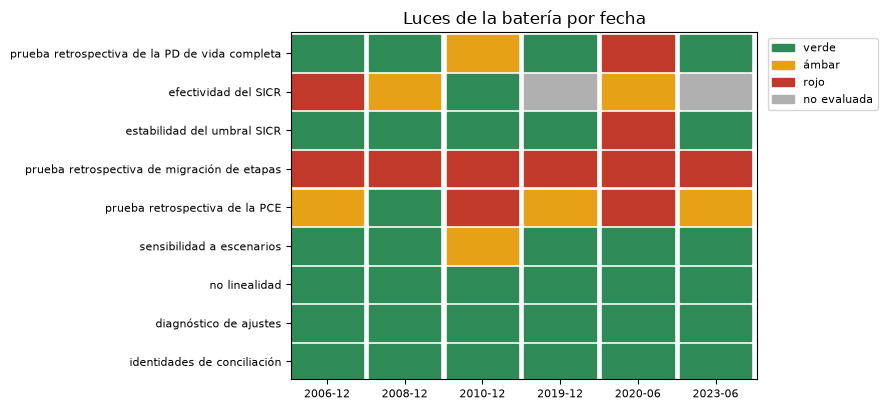

In [3]:
# Contar las luces de la batería y dibujarlas como una grilla de pruebas por fecha
lights = {tid: [tests[d]["ifrs9." + tid]["light"] for d in DATES] for tid in TEST_NAME}
total_cells = len(TEST_NAME) * len(DATES)
for light in COLOR:
    count = sum(row.count(light) for row in lights.values())
    print(LIGHT[light], ":", count, "de", total_cells, "celdas")

fig, ax = plt.subplots(figsize=(9, 4.2))
for i, (tid, row) in enumerate(lights.items()):
    for j, light in enumerate(row):
        ax.add_patch(plt.Rectangle((j, len(lights) - 1 - i), 0.92, 0.92, color=COLOR[light]))
ax.set_xlim(0, len(DATES))
ax.set_ylim(0, len(lights))
ax.set_xticks(np.arange(len(DATES)) + 0.46)
ax.set_xticklabels(DATES, fontsize=8)
ax.set_yticks(np.arange(len(lights)) + 0.46)
ax.set_yticklabels([TEST_NAME[t] for t in reversed(list(lights))], fontsize=8)
ax.legend(handles=[Patch(color=COLOR[k], label=LIGHT[k]) for k in COLOR], fontsize=8, loc="upper left",
          bbox_to_anchor=(1.01, 1.0))
ax.set_title("Luces de la batería por fecha")
fig.tight_layout()
plt.show()

De las 54 celdas (nueve pruebas, seis fechas) 34 son verdes, 7 ámbar, 11 rojas y 2 no evaluadas. Tres pruebas son verdes en todas las fechas: la no linealidad, el diagnóstico de ajustes y las identidades de conciliación, que verifican la aritmética del motor y las tablas de los cuadernos 03 y 04. La prueba de migración de etapas es roja en todas las fechas. Las filas informativas son las otras: la prueba retrospectiva de vida completa se pone roja en 2020-06, la efectividad del SICR es roja en 2006 y ámbar en 2008 y 2020-06, y la prueba retrospectiva de la PCE es verde solo en 2008.

### Paso 2: la prueba retrospectiva de la PD de vida completa

La prueba de vida completa compara la PD acumulada que predice el modelo para una cohorte de originación a 6, 12, ..., 36 meses con la tasa de incumplimiento acumulada observada (una estimación de Kaplan-Meier), y lee la mayor brecha. El artefacto guarda las curvas predicha y observada de la cohorte `all` y, en la fila versionada, la banda de Vasicek alrededor de la predicción. La celda llama a `lifetime_pd_backtest` del motor con esas curvas sin la correlación de activos, lo que le hace usar la regla de brecha relativa, y pone esa luz junto a la luz versionada, que usó la banda. La figura dibuja las dos curvas y la banda.

mayor brecha: 0.01669
mayor brecha relativa: 0.3228
luz sin la correlación: ámbar
luz con la correlación (la fila versionada): verde
horizontes dentro de la banda: 6 de 6


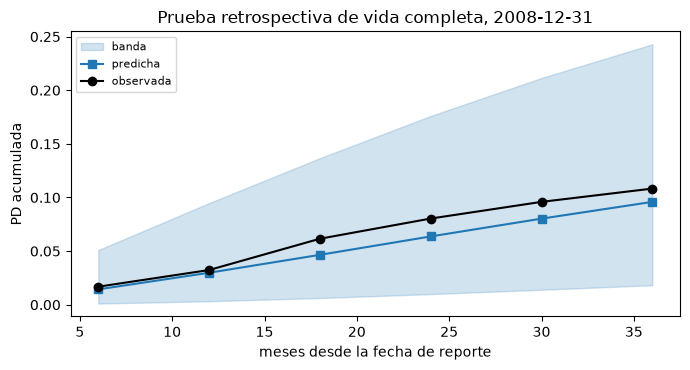

In [4]:
# Recalcular con el motor la prueba retrospectiva de vida completa de la cartera 2008 y dibujarla contra su banda
rows = [r for r in cases["2008-12"]["outputs"]["lifetime_backtest"]["rows"] if r["origination_cohort"] == "all"]
stored_row = tests["2008-12"]["ifrs9.lifetime_pd_backtest"]
months = np.array([r["months"] for r in rows])
pred = np.array([r["predicted_cumulative_pd"] for r in rows])
obs = np.array([r["observed_cumulative_pd"] for r in rows])
low, high = np.array(stored_row["extras"]["band_low"]), np.array(stored_row["extras"]["band_high"])
n_at_risk = np.full(months.size, stored_row["n"], dtype=float)
n_events = np.full(months.size, stored_row["n_events"], dtype=float)
result = ifrs9.lifetime_pd_backtest(months, pred, obs, n_at_risk, n_events, model_id="L1-dth", segment="all")
print("mayor brecha:", round(result.metric, 6))
print("mayor brecha relativa:", round(max(result.extras["relative_gap"]), 4))
print("luz sin la correlación:", LIGHT[result.light.value])
print("luz con la correlación (la fila versionada):", LIGHT[stored_row["light"]])
print("horizontes dentro de la banda:", int(np.sum((obs >= low) & (obs <= high))), "de", months.size)

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.fill_between(months, low, high, color="tab:blue", alpha=0.2, label="banda")
ax.plot(months, pred, color="tab:blue", marker="s", label="predicha")
ax.plot(months, obs, color="black", marker="o", label="observada")
ax.set_xlabel("meses desde la fecha de reporte")
ax.set_ylabel("PD acumulada")
ax.set_title("Prueba retrospectiva de vida completa, 2008-12-31")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

En la cartera 2008 la mayor brecha entre la PD acumulada predicha y la observada es 0,01669, y la curva observada queda dentro de la banda de Vasicek en los 6 de 6 horizontes, de modo que la luz versionada, que usa la banda, es verde. La llamada sin la correlación de activos usa la regla de brecha relativa, cuya mayor brecha relativa es 0,3228, y da ámbar. Ninguna está equivocada: la banda dice que la brecha es compatible con la correlación de incumplimientos que supone la política, y la regla relativa dice que la predicción a 36 meses está desviada en un tercio. La curva observada queda sobre la predicción en todos los horizontes, de modo que el modelo subpredice levemente, y un validador informa la regla junto con la luz.

### Paso 3: por cohorte de originación y por decil

La misma prueba corrida en cada cohorte de originación pregunta si el modelo está calibrado para los préstamos de cada año y no solo en promedio. La celda tabula la mayor brecha de cada cohorte para los tres peldaños del cuaderno 07, y lee la calibración por decil de PD predicha a 12 meses. La figura dibuja la PD acumulada observada contra la predicha de los diez deciles, con la línea de calibración perfecta, y la mayor brecha del peldaño `L1-dth` por cohorte, coloreada con la luz versionada.

cohorte    L0-km   L1-dth   L2-cox
older    0.0028   0.0015   0.0096
2004     0.0286   0.0349   0.0177
2005     0.0379   0.0575   0.0330
2006     0.0055   0.0359   0.0031
2007     0.1240   0.0859   0.1163
2008     0.0847   0.0445   0.0817
all      0.0427   0.0167   0.0427
razón observada sobre predicha por decil, 12 meses: [0.97 1.53 1.91 2.04 2.14 1.31 1.18 0.82 0.5  0.77]


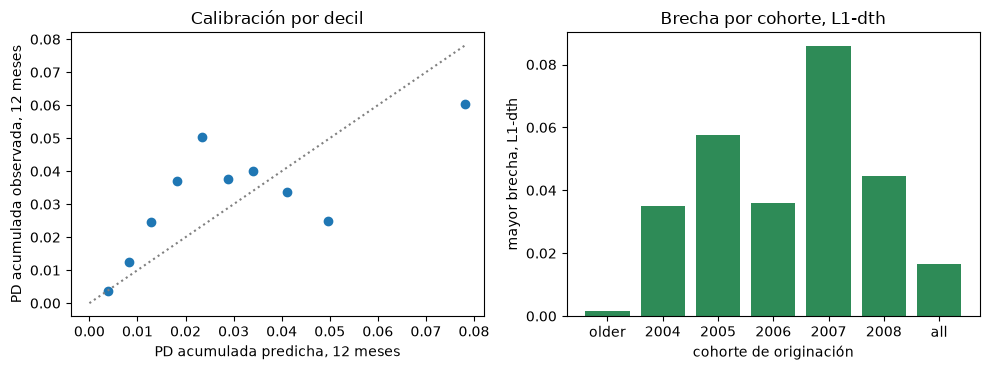

In [5]:
# Tabular la prueba de vida completa por cohorte y peldaño, y la calibración por decil, y dibujarlas
c08 = cases["2008-12"]
by = {(t["model_id"], t["segment"]): t for t in c08["tests"] if t["test_id"] == "ifrs9.lifetime_pd_backtest"}
cohorts = ["older", "2004", "2005", "2006", "2007", "2008", "all"]
rungs = ("L0-km", "L1-dth", "L2-cox")
print("cohorte", *[f"{r:>8s}" for r in rungs])
for cohort in cohorts:
    print(f"{cohort:6s}", *[f"{by[(r, cohort)]['metric']:8.4f}" for r in rungs])
deciles = [r for r in c08["outputs"]["decile_calibration"]["rows"] if r["months"] == 12]
predicted = np.array([r["predicted_cumulative_pd"] for r in deciles])
observed = np.array([r["observed_cumulative_pd"] for r in deciles])
print("razón observada sobre predicha por decil, 12 meses:", np.round(observed / predicted, 2))

fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.8))
left.scatter(predicted, observed, color="tab:blue")
left.plot([0, predicted.max()], [0, predicted.max()], color="grey", linestyle=":")
left.set_xlabel("PD acumulada predicha, 12 meses")
left.set_ylabel("PD acumulada observada, 12 meses")
left.set_title("Calibración por decil")
metrics = [by[("L1-dth", c)]["metric"] for c in cohorts]
right.bar(cohorts, metrics, color=[COLOR[by[("L1-dth", c)]["light"]] for c in cohorts])
right.set_xlabel("cohorte de originación")
right.set_ylabel("mayor brecha, L1-dth")
right.set_title("Brecha por cohorte, L1-dth")
fig.tight_layout()
plt.show()

El resultado agrupado esconde las cohortes. La cohorte 2007 es ámbar para el peldaño de Kaplan-Meier (0,1240) y el de Cox (0,1163) y verde para el peldaño de tiempo discreto (0,0859); la cohorte 2008 es ámbar para el peldaño de Cox; en la cohorte agrupada `all` los tres peldaños son verdes con brechas de 0,0427, 0,0167 y 0,0427. La calibración por decil a la izquierda no es monótona: la razón observada sobre predicha es 0,97 en el decil 1, sube a 2,14 en el decil 5 y cae a 0,50 en el decil 9 y a 0,77 en el decil 10. Los préstamos que el modelo llama más riesgosos incumplen menos de lo predicho y los intermedios más, así que el orden de la predicción es solo vagamente el orden de los resultados.

### Paso 4: ¿selecciona la Etapa 2 a los que incumplen? (efectividad del SICR)

Si la clasificación funciona, las cuentas en la Etapa 2 a la fecha de reporte deberían incumplir más seguido en el año siguiente que las cuentas en la Etapa 1. La métrica es la razón de las dos tasas de incumplimiento, $DR_{S2}/DR_{S1}$, verde desde 2, ámbar desde 1 y roja bajo 1; el área bajo la curva ROC de la etapa como clasificador se lee junto a ella. Las filas versionadas guardan los conteos de cada fecha, que la prueba del motor necesita a nivel de cuenta y el artefacto no guarda, así que la celda los lee. La figura dibuja las dos tasas de incumplimiento por fecha.

2006-12 rojo | DR2/DR1: 0.9662
   área bajo la curva ROC: 0.4999
2008-12 ámbar | DR2/DR1: 2.2525
   área bajo la curva ROC: 0.5256
2010-12 verde | DR2/DR1: 2.4376
   área bajo la curva ROC: 0.5783
2019-12 no evaluada | cuentas: 271801 | cuentas de Etapa 2: 0
2020-06 ámbar | DR2/DR1: 1.9951
   área bajo la curva ROC: 0.5085
2023-06 no evaluada | cuentas: 251636 | cuentas de Etapa 2: 0


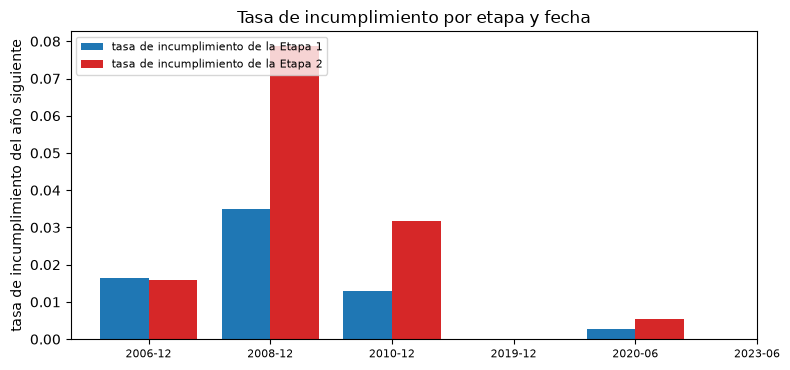

In [6]:
# Leer la efectividad del SICR de cada fecha desde las filas versionadas y dibujar las tasas de incumplimiento
dr1, dr2 = [], []
for d in DATES:
    row = tests[d]["ifrs9.sicr_effectiveness"]
    x = row["extras"]
    if row["light"] == "not_evaluated":
        stage2 = [r["accounts"] for r in cases[d]["outputs"]["stage_summary"]["rows"] if r["stage"] == "stage2"]
        print(d, LIGHT[row["light"]], "| cuentas:", row["n"], "| cuentas de Etapa 2:", sum(stage2))
        dr1.append(float("nan"))
        dr2.append(float("nan"))
        continue
    dr1.append(x["default_rate_stage1"])
    dr2.append(x["default_rate_stage2"])
    print(d, LIGHT[row["light"]], "| DR2/DR1:", round(row["metric"], 4))
    print("   área bajo la curva ROC:", round(x["roc_auc"], 4))

fig, ax = plt.subplots(figsize=(8, 3.8))
x_pos = np.arange(len(DATES))
ax.bar(x_pos - 0.2, dr1, width=0.4, color="tab:blue", label="tasa de incumplimiento de la Etapa 1")
ax.bar(x_pos + 0.2, dr2, width=0.4, color="tab:red", label="tasa de incumplimiento de la Etapa 2")
ax.set_xticks(x_pos)
ax.set_xticklabels(DATES, fontsize=8)
ax.set_ylabel("tasa de incumplimiento del año siguiente")
ax.set_title("Tasa de incumplimiento por etapa y fecha")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

La efectividad de la clasificación cambia con la fecha. La razón entre la tasa de incumplimiento de la Etapa 2 y la de la Etapa 1 es 0,9662 en 2006, roja: la Etapa 2 incumplió algo menos que la Etapa 1 y el área bajo la curva ROC es 0,4999, no mejor que una moneda. Es 2,2525 en 2008 (ámbar), 2,4376 en 2010 (verde) y 1,9951 en 2020-06 (ámbar, apenas bajo el corte verde de 2). En 2019-12 y 2023-06 no hay ninguna cuenta de Etapa 2, faltan las barras y la prueba no se puede evaluar. Donde se puede, el área bajo la curva se queda entre 0,4999 y 0,5783, un clasificador débil.

### Paso 5: el umbral no debe aflojarse cuando las condiciones empeoran

`sicr_threshold_stability` cuenta los períodos de reporte en que el multiplicador SICR implícito sube mientras sube también un índice de condiciones: aflojar el umbral justo cuando las condiciones empeoran. El artefacto guarda la cuenta versionada de cada fecha, y la función del motor corre sobre cualquier par de series, así que la celda la llama sobre tres series construidas, un multiplicador que baja al empeorar las condiciones, uno que se afloja dos veces y uno que sube con cada empeoramiento, e imprime las cuentas versionadas junto a ellas.

In [7]:
# Correr la prueba de estabilidad del umbral en tres series construidas y leer las filas versionadas
condition = np.array([1.0, 2.0, 3.0, 2.5, 4.0, 5.0])
series = {
    "el multiplicador baja al empeorar las condiciones": np.array([3.0, 2.8, 2.6, 2.6, 2.4, 2.2]),
    "dos períodos se aflojan": np.array([2.0, 2.0, 2.5, 2.5, 3.0, 3.0]),
    "el multiplicador sube con cada empeoramiento": np.array([2.0, 2.2, 2.5, 2.5, 2.8, 3.1]),
}
for label, multiplier in series.items():
    r = ifrs9.sicr_threshold_stability(multiplier, condition)
    print(f"{label:48s}", LIGHT[r.light.value], "| cuenta:", int(r.metric))
for d in DATES:
    x = tests[d]["ifrs9.sicr_threshold_stability"]["extras"]
    light = tests[d]["ifrs9.sicr_threshold_stability"]["light"]
    print(d, LIGHT[light], "| períodos que se aflojan:", len(x["loosening_periods"]), "de", x["periods"])

el multiplicador baja al empeorar las condiciones verde | cuenta: 0
dos períodos se aflojan                          ámbar | cuenta: 2
el multiplicador sube con cada empeoramiento     rojo | cuenta: 4
2006-12 verde | períodos que se aflojan: 0 de 2
2008-12 verde | períodos que se aflojan: 0 de 2
2010-12 verde | períodos que se aflojan: 0 de 2
2019-12 verde | períodos que se aflojan: 0 de 2
2020-06 rojo | períodos que se aflojan: 1 de 2
2023-06 verde | períodos que se aflojan: 0 de 2


Solo 2020-06 es rojo: uno de sus dos períodos se afloja, que es la mitad, y todas las demás fechas no tienen ninguno. En las series construidas el motor da verde para un multiplicador que baja al empeorar las condiciones, ámbar para dos períodos que se aflojan y rojo para cuatro. La prueba lee la dirección del umbral y nada más: dice que el umbral no se relajó justo cuando las condiciones empeoraron, y es ciega al nivel del multiplicador, que el cuaderno 02 mostró como la palanca que decide cuántos préstamos pasan a la Etapa 2.

### Paso 6: la prueba retrospectiva de migración de etapas

`stage_migration_backtest` compara una matriz predicha de 3 por 3 de transiciones de etapa a un año con los conteos observados mediante el chi-cuadrado anterior. Las filas versionadas son rojas en todas las fechas, y la celda imprime por qué: los grados de libertad, las filas omitidas y si una observación cayó en una celda que la predicción asigna en cero. Luego corre la función del motor sobre tres matrices construidas, una con conteos cercanos a la predicción, una con un solo conteo en una celda predicha en cero y una con conteos que se movieron mucho.

In [8]:
# Correr la prueba de migración en tres matrices construidas y leer las filas versionadas
for d in DATES:
    row = tests[d]["ifrs9.stage_migration_backtest"]
    x = row["extras"]
    print(d, LIGHT[row["light"]], "| cuentas comparadas:", row["n"])
    print("   grados de libertad:", x["degrees_of_freedom"])
    impossible = "sí" if x["impossible_cell_observed"] else "no"
    print("   filas omitidas:", x["rows_skipped"], "| celda imposible observada:", impossible)

predicted_matrix = np.array([[0.90, 0.08, 0.02], [0.20, 0.70, 0.10], [0.00, 0.00, 1.00]])
cases_built = {
    "conteos cercanos a la predicción": np.array([[905, 75, 20], [21, 68, 11], [0, 0, 10]]),
    "un conteo en una celda predicha en cero": np.array([[900, 80, 20], [20, 70, 10], [1, 0, 9]]),
    "conteos que se movieron mucho": np.array([[800, 150, 50], [40, 50, 10], [0, 0, 10]]),
}
for label, counts in cases_built.items():
    r = ifrs9.stage_migration_backtest(predicted_matrix, counts, model_id="lesson")
    statistic = round(r.statistic, 3) if math.isfinite(r.statistic) else "infinito"
    print(f"{label:44s}", LIGHT[r.light.value], "| estadístico:", statistic, "| valor p:", round(r.p_value, 4))

2006-12 rojo | cuentas comparadas: 225212
   grados de libertad: 1
   filas omitidas: 2 | celda imposible observada: sí
2008-12 rojo | cuentas comparadas: 273225
   grados de libertad: 1
   filas omitidas: 2 | celda imposible observada: sí
2010-12 rojo | cuentas comparadas: 248757
   grados de libertad: 4
   filas omitidas: 1 | celda imposible observada: no
2019-12 rojo | cuentas comparadas: 229819
   grados de libertad: 1
   filas omitidas: 2 | celda imposible observada: no
2020-06 rojo | cuentas comparadas: 232633
   grados de libertad: 1
   filas omitidas: 2 | celda imposible observada: sí
2023-06 rojo | cuentas comparadas: 205785
   grados de libertad: 1
   filas omitidas: 2 | celda imposible observada: no
conteos cercanos a la predicción             verde | estadístico: 0.547 | valor p: 0.9687
un conteo en una celda predicha en cero      rojo | estadístico: infinito | valor p: 0.0
conteos que se movieron mucho                rojo | estadístico: 143.075 | valor p: 0.0


La prueba de migración versionada es roja en las seis fechas, y la razón está en la matriz y no en falta de datos. En 2006, 2008 y 2020-06 una observación cae en una celda que la matriz predicha asigna en cero, de modo que el estadístico es infinito; en las otras fechas el estadístico es tan grande que el valor p es cero con muchos dígitos. En las matrices construidas el motor se comporta como fue diseñado: los conteos cercanos a la predicción dan un estadístico de 0,547 y un valor p de 0,9687, un solo conteo en una celda predicha en cero da un estadístico infinito, y los conteos que se movieron mucho dan 143,075. La prueba funciona, y lo que hay que revisar es la matriz predicha, en línea con el hallazgo `F-MIGRATION-red`.

### Paso 7: la prueba retrospectiva de la PCE, recalculada

La prueba retrospectiva de la PCE necesita dos números: la suma de las pérdidas descontadas realizadas en los 12 meses posteriores a la fecha de reporte y la suma de la PCE a 12 meses de las mismas cuentas. El artefacto guarda ambos para cada fecha, así que la celda recalcula $R_H$ y su luz con `ecl_backtest` del motor. La figura dibuja $R_H$ por fecha en un eje logarítmico, con la banda verde $[0{,}8, 1{,}25]$ y la banda ámbar $[0{,}5, 2{,}0]$ detrás.

2006-12 | realizada, USD millones: 342.8
   PCE, USD millones: 457.3
   R_H: 0.7496 ámbar
2008-12 | realizada, USD millones: 879.1
   PCE, USD millones: 840.5
   R_H: 1.046 verde
2010-12 | realizada, USD millones: 819.5
   PCE, USD millones: 1752.0
   R_H: 0.4678 rojo
2019-12 | realizada, USD millones: 325.7
   PCE, USD millones: 579.6
   R_H: 0.5619 ámbar
2020-06 | realizada, USD millones: 313.1
   PCE, USD millones: 4393.5
   R_H: 0.0713 rojo
2023-06 | realizada, USD millones: 496.0
   PCE, USD millones: 777.6
   R_H: 0.6378 ámbar


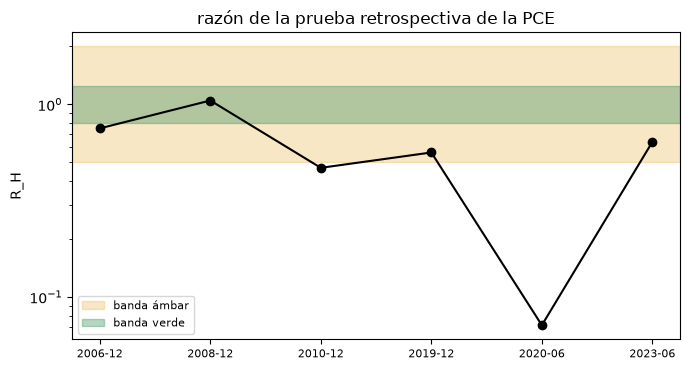

In [9]:
# Recalcular la razón de la prueba retrospectiva de la PCE de cada fecha desde sus dos sumas y dibujarla
r_values = []
for d in DATES:
    x = tests[d]["ifrs9.ecl_backtest"]["extras"]
    realised, expected = np.array([x["sum_realised"]]), np.array([x["sum_ecl"]])
    r = ifrs9.ecl_backtest(realised, expected, x["horizon_months"], model_id="L1-dth")
    r_values.append(r.metric)
    print(d, "| realizada, USD millones:", round(x["sum_realised"] / 1e6, 1))
    print("   PCE, USD millones:", round(x["sum_ecl"] / 1e6, 1))
    print("   R_H:", round(r.metric, 4), LIGHT[r.light.value])

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.axhspan(0.5, 2.0, color="#e6a117", alpha=0.25, label="banda ámbar")
ax.axhspan(0.8, 1.25, color="#2e8b57", alpha=0.35, label="banda verde")
ax.plot(range(len(DATES)), r_values, marker="o", color="black")
ax.set_yscale("log")
ax.set_xticks(range(len(DATES)))
ax.set_xticklabels(DATES, fontsize=8)
ax.set_ylabel("R_H")
ax.set_title("razón de la prueba retrospectiva de la PCE")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

La razón $R_H$ es 0,7496, 1,046, 0,4678, 0,5619, 0,0713 y 0,6378 en las seis fechas, y solo 2008 queda dentro de la banda verde de la figura. En cinco de las seis fechas la reserva excede la pérdida realizada del año siguiente. En 2020-06 la pérdida descontada realizada es 313,1 millones de USD frente a una PCE de 4.393,5 millones, una razón de 0,0713 muy por debajo de la banda ámbar, y la luz es roja. Un validador lo lee como una pregunta y no como un veredicto: o la PCE anticipó una pérdida que no llegó, o las pérdidas realizadas del año aún no están todas registradas.

### Paso 8: la sensibilidad a escenarios, recalculada

`scenario_sensitivity` necesita la PCE al 100% de cada escenario, las ponderaciones y la PCE en la trayectoria media, tal como las usó el cuaderno 03. El artefacto guarda las tres para cada fecha, así que la celda recalcula el índice de no linealidad y su luz para cada fecha, y pregunta si la PCE sube con la severidad del escenario, que es el orden que supone una sensibilidad.

In [10]:
# Recalcular la sensibilidad a escenarios de cada fecha desde su PCE de un solo escenario
for d in DATES:
    x = tests[d]["ifrs9.scenario_sensitivity"]["extras"]
    weights = np.array([s["weight"] for s in cases[d]["outputs"]["scenarios"]])
    single = np.array(x["single_scenario_ecl"])
    r = ifrs9.scenario_sensitivity(single, weights, x["ecl_at_mean_path"], model_id="L1-dth")
    ordered = bool(np.all(np.diff(single) >= 0))
    print(d, "| NL:", round(r.metric, 5), LIGHT[r.light.value])
    print("   la PCE sube con la severidad del escenario:", "sí" if ordered else "no")

2006-12 | NL: 0.00211 verde
   la PCE sube con la severidad del escenario: no
2008-12 | NL: 0.02121 verde
   la PCE sube con la severidad del escenario: no
2010-12 | NL: -0.00071 ámbar
   la PCE sube con la severidad del escenario: sí
2019-12 | NL: 0.0232 verde
   la PCE sube con la severidad del escenario: sí
2020-06 | NL: 0.01279 verde
   la PCE sube con la severidad del escenario: no
2023-06 | NL: 0.00622 verde
   la PCE sube con la severidad del escenario: sí


El índice es 0,00211, 0,02121, -0,00071, 0,0232, 0,01279 y 0,00622 en las seis fechas, verde en todas salvo 2010-12, donde la luz es ámbar porque el índice es negativo: una PCE ponderada bajo la PCE en la trayectoria media es inesperada para una pérdida convexa. La PCE sube con la severidad del escenario solo en 2010-12, 2019-12 y 2023-06. En 2006-12, 2008-12 y 2020-06 no sube, y esas son las fechas que llevan el hallazgo `F-SCENARIO-ORDER`, de modo que una sensibilidad construida sobre el orden de los escenarios se lee con ese hallazgo al lado.

### Paso 9: qué concluye un validador cuando una prueba no se puede evaluar

Al 2019-12-31 y al 2023-06-30 no hay ninguna cuenta de Etapa 2, así que la tasa de incumplimiento de la Etapa 2 no existe y `sicr_effectiveness` devuelve `not_evaluated` con una métrica indefinida. La celda reproduce con datos construidos y un generador con semilla las dos maneras en que una muestra puede hacer imposible la prueba: una muestra sin cuentas de Etapa 2 y una muestra con cuentas de Etapa 2 pero sin ningún incumplimiento en la Etapa 1. Luego lista las fechas de las filas versionadas que no están evaluadas.

In [11]:
# Correr la prueba de efectividad en muestras construidas donde no se puede evaluar
rng = np.random.default_rng(7)
n = 200
defaulted = rng.random(n) < 0.05
months_in_s2 = np.where(defaulted, 0.0, np.nan)
backstop = np.zeros(n, dtype=bool)
direct = defaulted.copy()
no_stage2 = ifrs9.sicr_effectiveness(np.ones(n), defaulted, 12, months_in_s2, direct, backstop, model_id="lesson")
print("ninguna cuenta de Etapa 2:", LIGHT[no_stage2.light.value])
print("   la métrica no está definida:", "sí" if math.isnan(no_stage2.metric) else "no")

stage = np.where(np.arange(n) < 20, 2.0, 1.0)
few = np.arange(n) < 3
months_few = np.where(few, 2.0, np.nan)
never = np.zeros(n, dtype=bool)
no_default_s1 = ifrs9.sicr_effectiveness(stage, few, 12, months_few, never, backstop, model_id="lesson")
print("ningún incumplimiento en la Etapa 1:", LIGHT[no_default_s1.light.value])
print("   la métrica no está definida:", "sí" if math.isnan(no_default_s1.metric) else "no")
missing = [d for d in DATES if tests[d]["ifrs9.sicr_effectiveness"]["light"] == "not_evaluated"]
print("fechas no evaluadas en las filas versionadas:", missing)

ninguna cuenta de Etapa 2: no evaluada
   la métrica no está definida: sí
ningún incumplimiento en la Etapa 1: no evaluada
   la métrica no está definida: sí
fechas no evaluadas en las filas versionadas: ['2019-12', '2023-06']


Las dos muestras construidas devuelven una luz de no evaluada con una métrica indefinida y no un número: sin cuentas de Etapa 2 no existe la tasa de incumplimiento de la Etapa 2, y sin incumplimientos en la Etapa 1 la razón tiene un denominador cero. Las filas versionadas dicen lo mismo para 2019-12 y 2023-06. Un validador lee una prueba no evaluada como la ausencia de un resultado. El informe debe decir que la clasificación no se probó en esas fechas, y no debe contarlas entre las pruebas que pasaron.

## Resultados

**Respuesta:** No: de las 54 celdas de la batería (nueve pruebas en seis fechas) 34 son verdes, 7 ámbar, 11 rojas y 2 no evaluadas, y el modelo falla donde un validador mira primero: la prueba de migración de etapas es roja en las seis fechas, la razón de la prueba retrospectiva de la PCE queda en la banda verde solo en 2008 (1,046) y cae a 0,0713 en 2020-06, y la razón de efectividad del SICR es 0,9662 en 2006 y no se puede calcular en 2019-12 y 2023-06, donde ningún préstamo está en la Etapa 2, lo que un informe debe declarar como no probado y nunca como aprobado.

- **La batería en una grilla.** Tres pruebas son verdes en todas las fechas: la no linealidad, el diagnóstico de ajustes y las identidades de conciliación, que verifican la aritmética del motor y las tablas (cuadernos 03 y 04). La prueba de migración de etapas es roja en todas las fechas. Las filas informativas son las otras.
- **La prueba de PD de vida completa depende de su regla.** En 2008 la mayor brecha en la cohorte `all` es 0,01669 y la curva observada queda dentro de la banda versionada en los 6 de 6 horizontes, de modo que la luz versionada es verde. La llamada sin la correlación de activos usa la regla de brecha relativa, cuya mayor brecha relativa es 0,3228, y da ámbar. Un validador informa la regla con la luz.
- **El resultado agrupado esconde las cohortes.** La cohorte 2007 es ámbar para el peldaño de Kaplan-Meier (0,1240) y el de Cox (0,1163) y verde para el de tiempo discreto (0,0859). La calibración por decil no es monótona: la razón observada sobre predicha es 0,97 en el decil 1, 2,14 en el decil 5 y 0,50 en el decil 9.
- **La efectividad del SICR cambia con la fecha.** La razón de las tasas de incumplimiento es 0,9662 en 2006 (roja), 2,2525 en 2008 (ámbar), 2,4376 en 2010 (verde) y 1,9951 en 2020-06 (ámbar), con un área bajo la curva ROC entre 0,4999 y 0,5783.
- **La prueba de estabilidad del umbral se dispara una vez.** Solo 2020-06 es roja, con uno de dos períodos que se aflojan. En series construidas el motor da verde para ninguno, ámbar para dos períodos que se aflojan y rojo para cuatro.
- **La prueba de migración de etapas es roja en todas partes, por una razón que un validador debe leer.** En 2006, 2008 y 2020-06 una observación cae en una celda que la matriz predicha asigna en cero. Los casos construidos muestran ambos lados: conteos cercanos a la predicción dan un estadístico de 0,547 y un valor p de 0,9687, y conteos que se movieron dan 143,075.
- **La prueba retrospectiva de la PCE dice que la reserva estuvo sobre la pérdida realizada en cinco de seis fechas.** $R_H$ es 0,7496, 1,046, 0,4678, 0,5619, 0,0713 y 0,6378, y solo 2008 es verde. En 2020-06 la pérdida descontada realizada es 313,1 millones de USD frente a una PCE de 4.393,5 millones.
- **La sensibilidad a escenarios** muestra que la PCE sube con la severidad del escenario en 2010-12, 2019-12 y 2023-06 y no en 2006-12, 2008-12 y 2020-06, las fechas que llevan el hallazgo `F-SCENARIO-ORDER`. En 2010-12 el índice es negativo ($-0{,}00071$), ámbar.
- **Una prueba que no se puede evaluar no es una prueba aprobada.** En 2019-12 y 2023-06 no hay ninguna cuenta de Etapa 2, así que la prueba de efectividad devuelve no evaluada con una métrica indefinida.

Lo que este cuaderno no muestra: las luces son las compuertas internas de Contraste, no umbrales regulatorios, y los resultados observados son castigos de préstamos de la SBA, no incumplimientos de una cartera hipotecaria. Las pruebas cuyos insumos a nivel de cuenta los artefactos no guardan (la efectividad y la migración de las fechas versionadas) se leen de sus filas y se ejercitan sobre datos construidos.

## Resumen

- La batería IFRS 9 tiene nueve pruebas, cada una una función del motor que devuelve un `TestResult`, cada una una compuerta interna con sus parámetros registrados en la fila.
- Se recalcula lo que permiten los insumos del artefacto (la métrica de vida completa, la prueba retrospectiva de la PCE, la sensibilidad a escenarios) y el resto se lee como filas versionadas, ejercitando el motor sobre datos construidos donde los insumos no se guardan.
- Una luz depende de su regla: la prueba de vida completa es verde con la banda de Vasicek y ámbar con la brecha relativa sobre los mismos números, de modo que un informe declara la regla.
- El resultado agrupado esconde cohortes y deciles; la efectividad de la clasificación cambia con la fecha y no es evaluable cuando no hay Etapa 2.
- Una prueba que no se puede evaluar es la ausencia de un resultado; la prueba de migración de etapas es roja en todas las fechas y la razón está en sus filas.

**Qué probar después.** Abre las filas de Kaplan-Meier y de Cox de 2008 y compara sus brechas por cohorte con el peldaño de tiempo discreto; cambia la `predicted_matrix` construida del paso 6 de modo que la celda en cero sea pequeña pero positiva. Luego sigue con el cuaderno 06, que provisiona un banco bajo tres regímenes.

## Referencias

- EBA (2023), IFRS 9 implementation by EU institutions, informe de seguimiento 2023, EBA/Rep/2023/36, párrafos 29 a 33 y 94 a 118. https://www.eba.europa.eu/sites/default/files/2023-11/25b12d35-9c28-4335-a589-166c77198920/Final%20Report%20on%20IFRS9%20implementation%20by%20EU%20institutions.pdf
- EBA (2021), IFRS 9 implementation by EU institutions, informe de seguimiento, EBA/Rep/2021/35. https://www.eba.europa.eu/sites/default/files/document_library/Publications/Reports/2021/1024609/IFRS9%20monitoring%20report.pdf
- BCBS (2015), Guidance on credit risk and accounting for expected credit losses (d350), párrafos 36, 50 y 51 y párrafo A26 del anexo. https://www.bis.org/bcbs/publ/d350.htm
- IASB, IFRS 9 Instrumentos financieros (julio de 2014), tal como lo adopta el Reglamento (UE) 2016/2067 de la Comisión, párrafos 5.5 y B5.5, y las enmiendas a la IFRS 7, 35A a 35N. https://eur-lex.europa.eu/legal-content/EN/TXT/HTML/?uri=CELEX:32016R2067
- Anderson, T. W. y Goodman, L. A. (1957), Statistical inference about Markov chains, Annals of Mathematical Statistics 28(1), ecuación (3.1). https://doi.org/10.1214/aoms/1177707039
- GPPC (2016), The implementation of IFRS 9 impairment requirements by banks, 17 de junio de 2016, secciones 2.1.1, 2.7.2 y 2.8.1.2. https://www.globalpublicpolicycommittee.org/wp-content/uploads/2022/12/gppc-ifrs9-implementation-considerations-20160617.pdf